## Task

For **each** of the two series (`series1` and `series2`), find an ARIMA(p, 0, q) model that reasonably fits the data. Your analysis should include the following steps:

0. **Estimation/test split.** Partition each series into an estimation (training) set with the first 90% of the observations and a test set with the last 10%. Do not shuffle: the order of a time series matters.
1. **Time series plot** of the training set (the first 90% of the data)
2. **ACF and PACF diagrams** of the estimation set.
3. **Choice of candidate models** (values of p and q) based on the ACF/PACF. Justify the choice.
4. **Table with the estimated coefficients** of each candidate model: coefficient, standard error and p-value.
5. **AIC and BIC** of all candidate models.
6. **Residual analysis of the best model:** residual plot, residual ACF and Ljung-Box tests.
7. **Forecast** of the test set with the best model, and the **mean squared error (MSE)** on the test set.
8. **Choice of the "best" model.** Explain how you selected the model.

## The presentation

- The notebook is your presentation so don't create separate Powerpoint (or similar) files.
- The notebook must not contain prose in markdown (text) other than the instructions here.
- The notebook must not contain printed text other than simple values, e.g. AIC=-493, BIC=-592, MSE=1239 etc. Apart from this, the only
allowed output from code are tables and plots.
- Keep the generated code _simple_. The assignment does not require a lot of programming so if the AI assistant outputs
large chunks of code, make sure to trim these down.

> **Note.** During the presentation you must be able to explain **each diagram and each test**: what it does, why it is used, what conclusions _can_ be drawn from it and what your conclusions are in in the specific case. Expect questions both on the **theory** and on your **concrete results**.

## Submission

The submission **deadline is 22.11.2026 18:00** Sofia local time.

After opening this notebook, save it in your Google drive. Edit it according to the task and keep saving it to your Google drive.
When you are finished with the assignment, click on the "Run All" button in Colab to make sure that it contains all outputs and runs without errors (check for errors!).


1) Download the notebook (File -> Download -> .ipynb (NOT .py))
2) Find the "Share" button in Colab, copy the link and also submit it in Moodle (online text). **Make sure that the link points to your notebook, not to the assignment template in Github**
3) Upload the notebook in Moodle
4) Only one member of the group needs to submit the notebook so make sure that you have written
your names and student ids in the code cell above.


## Task

For **each** of the two series (`series1` and `series2`), find an ARIMA(p, 0, q) model that reasonably fits the data. Your analysis should include the following steps:

0. **Estimation/test split.** Partition each series into an estimation (training) set with the first 90% of the observations and a test set with the last 10%. Do not shuffle: the order of a time series matters.
1. **Time series plot** of the training set (the first 90% of the data)
2. **ACF and PACF diagrams** of the estimation set.
3. **Choice of candidate models** (values of p and q) based on the ACF/PACF. Justify the choice.
4. **Table with the estimated coefficients** of each candidate model: coefficient, standard error and p-value.
5. **AIC and BIC** of all candidate models.
6. **Residual analysis of the best model:** residual plot, residual ACF and Ljung-Box tests.
7. **Forecast** of the test set with the best model, and the **mean squared error (MSE)** on the test set.
8. **Choice of the "best" model.** Explain how you selected the model.

## The presentation

- The notebook is your presentation so don't create separate Powerpoint (or similar) files.
- The notebook must not contain prose in markdown (text) other than the instructions here.
- The notebook must not contain printed text other than simple values, e.g. AIC=-493, BIC=-592, MSE=1239 etc. Apart from this, the only
allowed output from code are tables and plots.
- Keep the generated code _simple_. The assignment does not require a lot of programming so if the AI assistant outputs
large chunks of code, make sure to trim these down.

> **Note.** During the presentation you must be able to explain **each diagram and each test**: what it does, why it is used, what conclusions _can_ be drawn from it and what your conclusions are in in the specific case. Expect questions both on the **theory** and on your **concrete results**.

## Submission

The submission **deadline is 22.11.2026 18:00** Sofia local time.

After opening this notebook, save it in your Google drive. Edit it according to the task and keep saving it to your Google drive.
When you are finished with the assignment, click on the "Run All" button in Colab to make sure that it contains all outputs and runs without errors (check for errors!).


1) Download the notebook (File -> Download -> .ipynb (NOT .py))
2) Find the "Share" button in Colab, copy the link and also submit it in Moodle (online text). **Make sure that the link points to your notebook, not to the assignment template in Github**
3) Upload the notebook in Moodle
4) Only one member of the group needs to submit the notebook so make sure that you have written
your names and student ids in the code cell above.


# Time Series Analysis 2026, Presentation I

## Participant Information

Write your **student IDs** and **names** into the variables in the next cell (`name1`, `studentId1`, and, if you work in a pair, `name2`, `studentId2`). Replace the placeholder text; keep the quotation marks.

**Example for a group of two students**, Sylvia Petrova (7EB0120130) and Petko Petrov (8EB0120132):

```python
name1 = "Sylvia Petrova"
studentId1 = "7EB0120130"
name2 = "Petko Petrov"
studentId2 = "8EB0120132"
```

**Single-person group:** fill in `name1` and `studentId1` only and leave `name2` and `studentId2` untouched (do not edit them). You will then see a warning about the missing second name, which you can ignore.

- At least one name is required. The notebook will stop with an error if `name1` and `name2` are both missing or still contain the defaults.
- The two time series you analyse are selected **at random from your names**, so the same names always give the same series. Please spell your names consistently (capitalisation and extra spaces are ignored).

In [1]:
name1 = "Georgi Totev"
studentId1 = "0EB0100174"

name2 = ""
studentId2 = ""

In [2]:
###########################
## DO NOT EDIT THIS CELL ##
###########################

import hashlib
import pandas as pd
import random
import warnings


DEFAULT_NAME1 = "YOUR NAME HERE, e.g. Petko Petrov"
DEFAULT_ID1 = "e.g. 0EB0493240"


def is_filled(value, *defaults):
    value = value.strip()
    return value != "" and value not in defaults


has_name1 = is_filled(name1, DEFAULT_NAME1)
has_name2 = is_filled(name2)

if not (has_name1 or has_name2):
    raise ValueError("Please write at least one name (name1) in the cell above.")

if not has_name2:
    warnings.warn("The second name (name2) is missing or still has the default value. "
                  "Ignore this warning if you submit alone.")
if not is_filled(studentId1, DEFAULT_ID1):
    warnings.warn("studentId1 is missing or still has the default value.")
if has_name2 and not is_filled(studentId2, "..."):
    warnings.warn("studentId2 is missing or still has the default value.")

BASE_URL = "https://raw.githubusercontent.com/febse/data/main/ts/ts2026"
N_SERIES = 50

# Seed derived from the names (order, case and spaces do not matter).
# hashlib is used because Python's built-in hash() changes between sessions.
names = sorted(" ".join(n.lower().split()) for n, ok in [(name1, has_name1), (name2, has_name2)] if ok)
seed = int(hashlib.sha256("|".join(names).encode("utf-8")).hexdigest(), 16)
rng = random.Random(seed)

file1 = f"batch1_{rng.randint(1, N_SERIES):02d}.csv"
file2 = f"batch2_{rng.randint(1, N_SERIES):02d}.csv"
print("Selected series:", file1, file2)

series1 = pd.read_csv(f"{BASE_URL}/{file1}")
series2 = pd.read_csv(f"{BASE_URL}/{file2}")

/tmp/ipykernel_88461/2690516268.py:27: UserWarning: The second name (name2) is missing or still has the default value. Ignore this warning if you submit alone.
  warnings.warn("The second name (name2) is missing or still has the default value. "


Selected series: batch1_30.csv batch2_11.csv


## Task

For **each** of the two series (`series1` and `series2`), find an ARIMA(p, 0, q) model that reasonably fits the data. Your analysis should include the following steps:

0. **Estimation/test split.** Partition each series into an estimation (training) set with the first 90% of the observations and a test set with the last 10%. Do not shuffle: the order of a time series matters.
1. **Time series plot** of the training set (the first 90% of the data)
2. **ACF and PACF diagrams** of the estimation set.
3. **Choice of candidate models** (values of p and q) based on the ACF/PACF. Justify the choice.
4. **Table with the estimated coefficients** of each candidate model: coefficient, standard error and p-value.
5. **AIC and BIC** of all candidate models.
6. **Residual analysis of the best model:** residual plot, residual ACF and Ljung-Box tests.
7. **Forecast** of the test set with the best model, and the **mean squared error (MSE)** on the test set.
8. **Choice of the "best" model.** Explain how you selected the model.

## The presentation

- The notebook is your presentation so don't create separate Powerpoint (or similar) files.
- The notebook must not contain prose in markdown (text) other than the instructions here.
- The notebook must not contain printed text other than simple values, e.g. AIC=-493, BIC=-592, MSE=1239 etc. Apart from this, the only
allowed output from code are tables and plots.
- Keep the generated code _simple_. The assignment does not require a lot of programming so if the AI assistant outputs
large chunks of code, make sure to trim these down.

> **Note.** During the presentation you must be able to explain **each diagram and each test**: what it does, why it is used, what conclusions _can_ be drawn from it and what your conclusions are in in the specific case. Expect questions both on the **theory** and on your **concrete results**.

## Submission

The submission **deadline is 22.11.2026 18:00** Sofia local time.

After opening this notebook, save it in your Google drive. Edit it according to the task and keep saving it to your Google drive.
When you are finished with the assignment, click on the "Run All" button in Colab to make sure that it contains all outputs and runs without errors (check for errors!).


1) Download the notebook (File -> Download -> .ipynb (NOT .py))
2) Find the "Share" button in Colab, copy the link and also submit it in Moodle (online text). **Make sure that the link points to your notebook, not to the assignment template in Github**
3) Upload the notebook in Moodle
4) Only one member of the group needs to submit the notebook so make sure that you have written
your names and student ids in the code cell above.


In [3]:
# Partition series1 (100 observations: 90 estimation, 10 test)
split_idx1 = int(len(series1) * 0.90)
train1 = series1.iloc[:split_idx1]
test1 = series1.iloc[split_idx1:]

# Partition series2 (100 observations: 90 estimation, 10 test)
split_idx2 = int(len(series2) * 0.90)
train2 = series2.iloc[:split_idx2]
test2 = series2.iloc[split_idx2:]

print(f"Series 1 - Train shape: {train1.shape}, Test shape: {test1.shape}")
print(f"Series 2 - Train shape: {train2.shape}, Test shape: {test2.shape}")

Series 1 - Train shape: (90, 2), Test shape: (10, 2)
Series 2 - Train shape: (90, 2), Test shape: (10, 2)


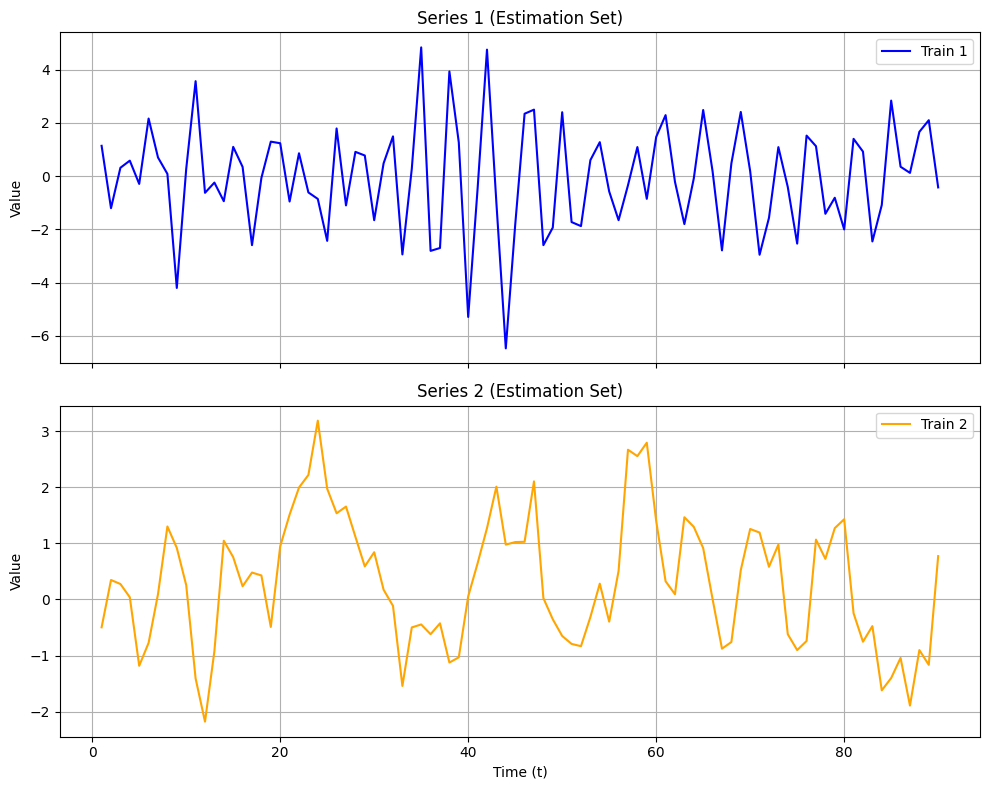

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Plot train1
axes[0].plot(train1['t'], train1['y'], color='blue', label='Train 1')
axes[0].set_title('Series 1 (Estimation Set)')
axes[0].set_ylabel('Value')
axes[0].grid(True)
axes[0].legend()

# Plot train2
axes[1].plot(train2['t'], train2['y'], color='orange', label='Train 2')
axes[1].set_title('Series 2 (Estimation Set)')
axes[1].set_xlabel('Time (t)')
axes[1].set_ylabel('Value')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

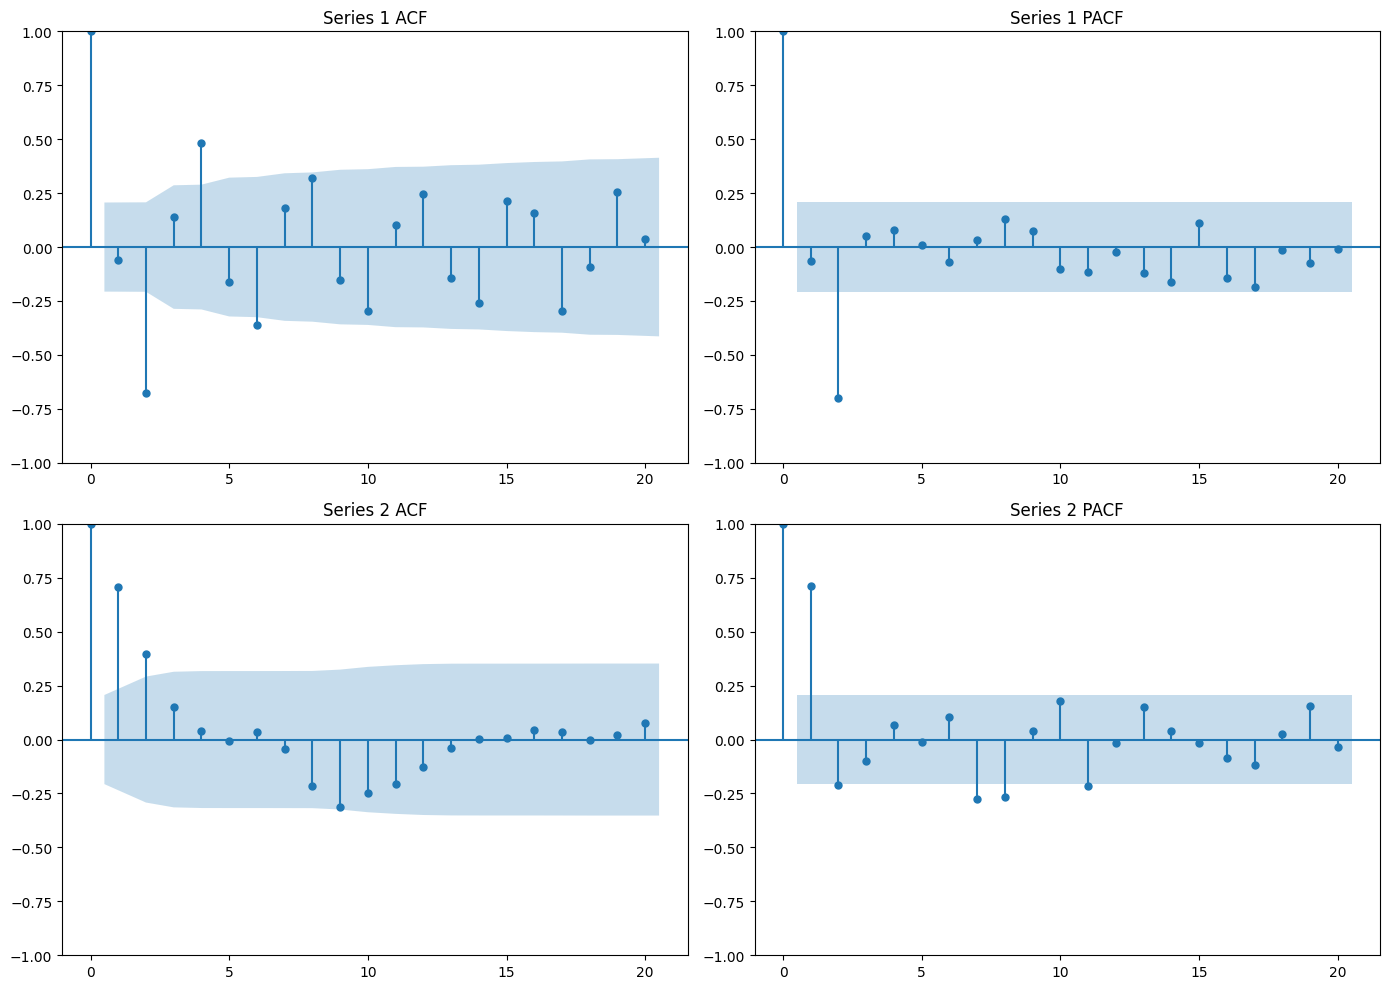

In [5]:
import statsmodels.api as sm
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Series 1 ACF & PACF
sm.graphics.tsa.plot_acf(train1['y'], lags=20, ax=axes[0, 0], title='Series 1 ACF')
sm.graphics.tsa.plot_pacf(train1['y'], lags=20, ax=axes[0, 1], title='Series 1 PACF', method='yw')

# Series 2 ACF & PACF
sm.graphics.tsa.plot_acf(train2['y'], lags=20, ax=axes[1, 0], title='Series 2 ACF')
sm.graphics.tsa.plot_pacf(train2['y'], lags=20, ax=axes[1, 1], title='Series 2 PACF', method='yw')

plt.tight_layout()
plt.show()